# 05 · Unsupervised landscape typology
**Question.** Does the landscape, summarised *without* drying labels or survey fields, structure drying?

**Method.** 23+ continuous GIS covariates (terrain, catchment hydrology, climate, water balance, vegetation, roads,
and the GEE enrichment layers) → standardisation → PCA (90 % variance) → Gaussian mixtures (K = 2–12) selected by BIC
subject to bootstrap stability (mean ARI ≥ 0.75; rule fixed before looking at drying). Density-based check with
HDBSCAN, visual check with t-SNE, landscape anomalies with an isolation forest (`src/unsupervised.py`).

In [1]:
import sys, os, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)
M, F = ROOT / "results/metrics", ROOT / "results/figures"
def table(name, **kw):
    t = pd.read_csv(M / name, **kw)
    return t.round(4)
def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.unsupervised import LANDSCAPE_COLS
print(len(LANDSCAPE_COLS), "landscape covariates:"); print(", ".join(LANDSCAPE_COLS))

46 landscape covariates:
elevation_m, slope_deg, aspect_sin, aspect_cos, precip_annual_mm, precip_monsoon_mm, precip_dry_season_mm, ndvi_mean, ndwi_mean, log_upa, hnd, elv, twi, tpi_500m, tri_90m, precip_dry_deficit_mm, precip_mon_deficit_mm, aet, def, soil, pdsi, dist_to_road_m, road_density_500m, wc_tree, wc_shrub, wc_grass, wc_crop, wc_built, wc_bare, wc_water, gfc_treecover2000, gfc_loss_pre2015, soil_clay, soil_sand, soil_soc, soil_bdod, et_mean, chirps_trend, chirps_anom_2015, built_2020, pop_1km, nightlights, landform_position, chili, mtpi, topo_diversity


## PCA

In [3]:
display(table("un_pca_variance.csv").T)
l = pd.read_csv(M / "un_pca_loadings.csv", index_col=0)
l.iloc[:, :4].round(2).sort_values("PC1")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
pc,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19
explained_variance_ratio,0.2346,0.1475,0.0966,0.0574,0.0502,0.0389,0.0348,0.0326,0.0296,0.0252,0.0244,0.0221,0.0197,0.0185,0.0162,0.0153,0.0145,0.0135,0.0123


,PC1,PC2,PC3,PC4
soil_bdod,-0.24,0.15,-0.08,0.06
ndwi_mean,-0.20,-0.08,-0.04,0.20
wc_crop,-0.20,-0.12,-0.07,0.05
pop_1km,-0.19,-0.15,-0.01,-0.10
def,-0.18,0.26,0.04,-0.04
pdsi,-0.18,0.22,0.12,-0.11
aet,-0.18,0.28,0.09,-0.04
road_density_500m,-0.18,-0.19,0.06,0.03
built_2020,-0.18,-0.23,-0.02,0.04
nightlights,-0.18,-0.21,0.00,-0.05


## Model selection: BIC and bootstrap stability

In [4]:
table("un_typology_selection.csv")

,K,bic,stability_ari_mean,stability_ari_sd,min_type_share,selected
0,2,306498.1339,0.9464,0.0259,0.1455,False
1,3,297834.8359,0.9446,0.0280,0.0432,False
2,4,284895.3361,0.8920,0.0729,0.0408,False
3,5,278939.2358,0.4664,0.2171,0.0355,False
4,6,275112.5717,0.5562,0.1788,0.0464,False
5,7,270704.6010,0.7347,0.1827,0.0396,False
6,8,267640.9655,0.8393,0.1147,0.0357,True
7,9,265670.7478,0.6597,0.0779,0.0388,False
8,10,263686.9710,0.6487,0.0947,0.0060,False
9,11,263192.7561,0.5661,0.0708,0.0218,False


## Types, their profiles and drying rates

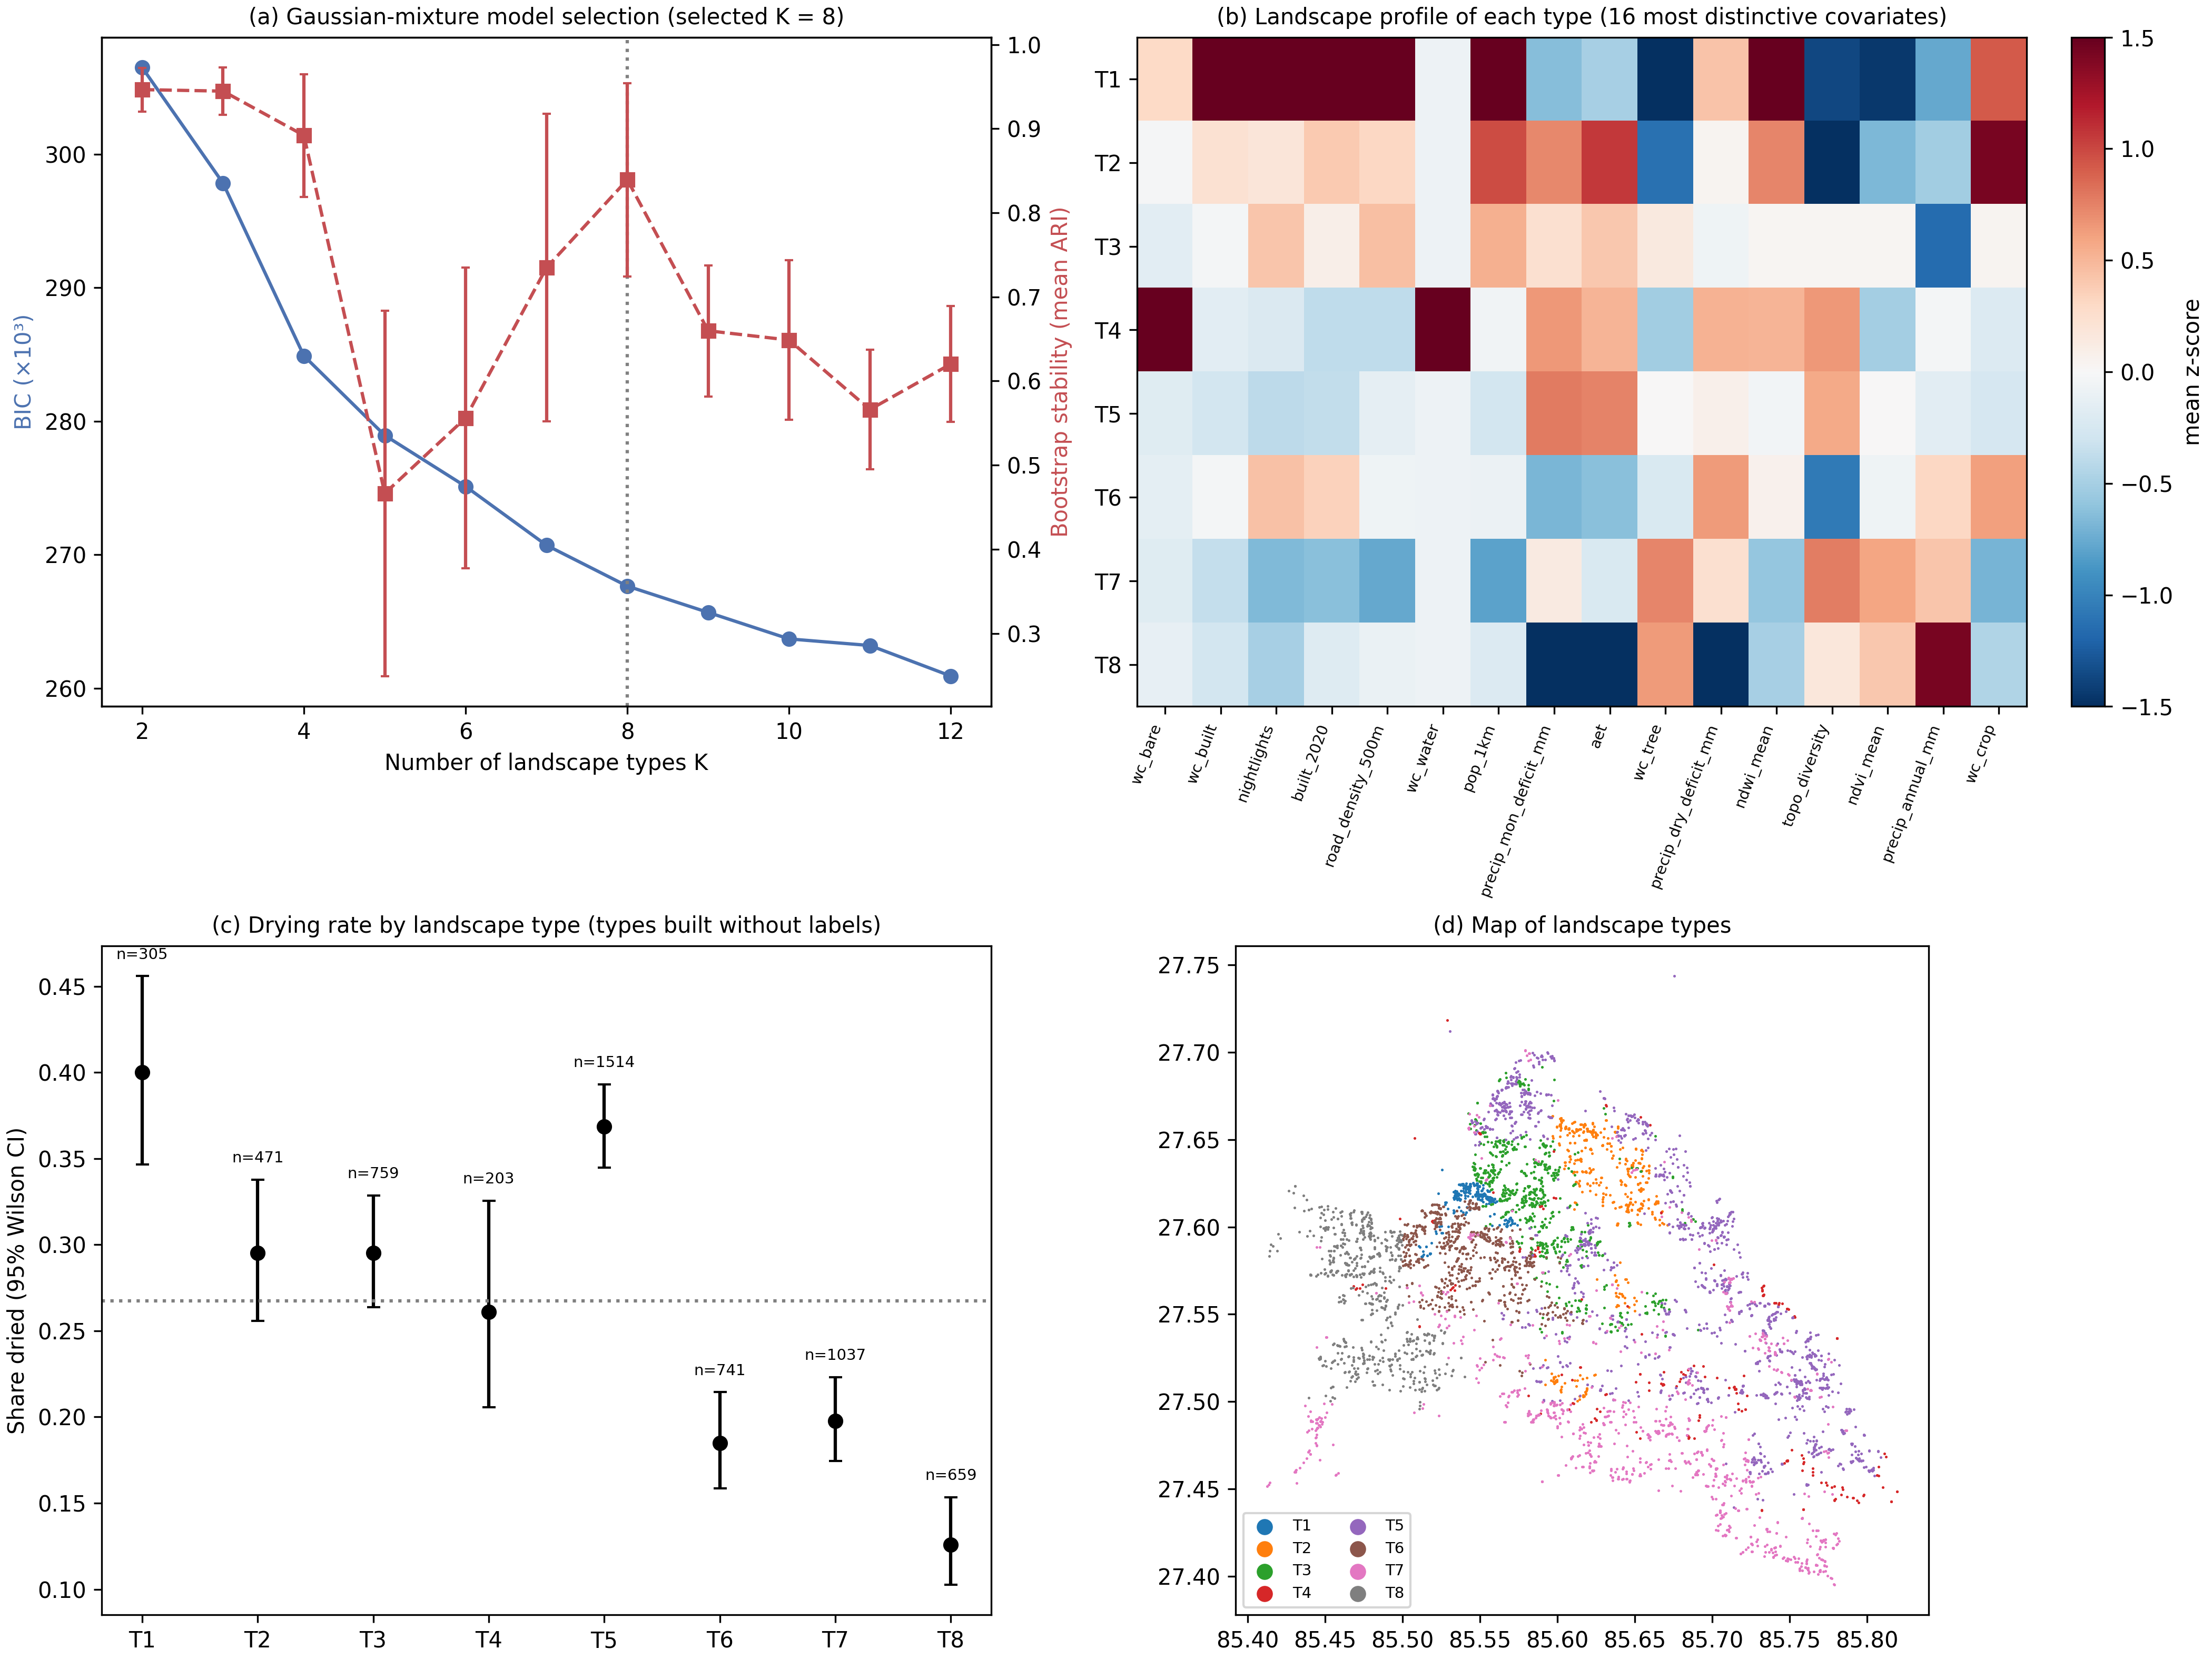

In [5]:
fig("un_typology.png")

In [6]:
display(table("un_typology_drying.csv"))
pd.read_csv(M / "un_typology_profiles.csv", index_col=0).T.round(2)

,type,n_sources,share_ponds,n_wards_present,drying_rate,ci_low,ci_high
0,T1,305,0.1902,14,0.4000,0.3466,0.4559
1,T2,471,0.2845,23,0.2951,0.2557,0.3378
2,T3,759,0.1028,33,0.2951,0.2638,0.3285
3,T4,203,0.0493,38,0.2611,0.2055,0.3255
4,T5,1514,0.0911,48,0.3686,0.3446,0.3932
5,T6,741,0.0364,24,0.1849,0.1586,0.2144
6,T7,1037,0.0608,55,0.1977,0.1746,0.2230
7,T8,659,0.0197,12,0.1259,0.1028,0.1535


,T1,T2,T3,T4,T5,T6,T7,T8
elevation_m,0.39,-1.41,-0.20,-1.27,-0.50,0.44,0.49,1.33
slope_deg,-1.07,-1.17,0.09,-0.08,0.39,-0.55,0.54,0.13
aspect_sin,-0.38,-0.04,0.23,0.08,0.06,-0.29,-0.06,0.19
aspect_cos,-0.37,-0.22,0.24,0.05,0.03,-0.27,0.28,-0.18
precip_annual_mm,-0.77,-0.52,-1.16,-0.03,-0.16,0.31,0.41,1.43
precip_monsoon_mm,-0.75,-0.49,-1.16,-0.04,-0.16,0.36,0.40,1.39
precip_dry_season_mm,-1.30,0.12,-1.02,-0.03,0.39,-0.36,0.18,0.91
ndvi_mean,-1.45,-0.68,0.03,-0.51,0.01,-0.06,0.59,0.41
ndwi_mean,1.56,0.73,0.03,0.51,-0.04,0.07,-0.58,-0.50
log_upa,-0.39,0.22,-0.20,0.63,0.00,-0.16,0.13,0.03


## Type vs ward (likelihood-ratio tests, Cramér's V)

In [7]:
display(table("un_typology_vs_ward_lrt.csv")); table("un_typology_summary.csv")

,test,lr_stat,df,p,adj_pseudo_r2_model
0,type (vs null),237.5356,7,0.0,0.0338
1,ward (vs null),846.0502,74,0.0,0.1057
2,type | ward,55.9202,7,0.0,0.1120
3,ward | type,664.4348,74,0.0,0.1120


,chi2,df,p,cramers_v_type_drying,cramers_v_ward_drying,cramers_v_type_ward
0,230.1446,7,0.0,0.1981,0.3583,0.7416


## Density-based clusters (HDBSCAN), t-SNE and anomalies

In [8]:
display(table("un_hdbscan_clusters.csv")); display(table("un_hdbscan_summary.csv")); table("un_anomalies.csv")

,cluster,n_sources,drying_rate,ci_low,ci_high,dominant_landscape_type,share_dominant_type
0,noise,2500,0.2688,0.2518,0.2865,T7,0.2864
1,D1,2987,0.2769,0.2611,0.2932,T5,0.2728
2,D2,202,0.1089,0.0730,0.1594,T7,0.9802


,n_clusters,noise_share,ari_with_types_core,cramers_v_cluster_drying
0,2,0.4394,0.0396,0.0667


,n_anomalous,drying_rate_anomalous,drying_rate_typical,odds_ratio,fisher_p,n_wards_with_anomalies,max_share_in_one_ward,anomaly_share_by_type
0,285,0.3368,0.2637,1.4183,0.0074,43,0.1158,T1: 0.243; T2: 0.011; T3: 0.004; T4: 0.433; T5: 0.005; T6: 0.008; T7: 0.055;...


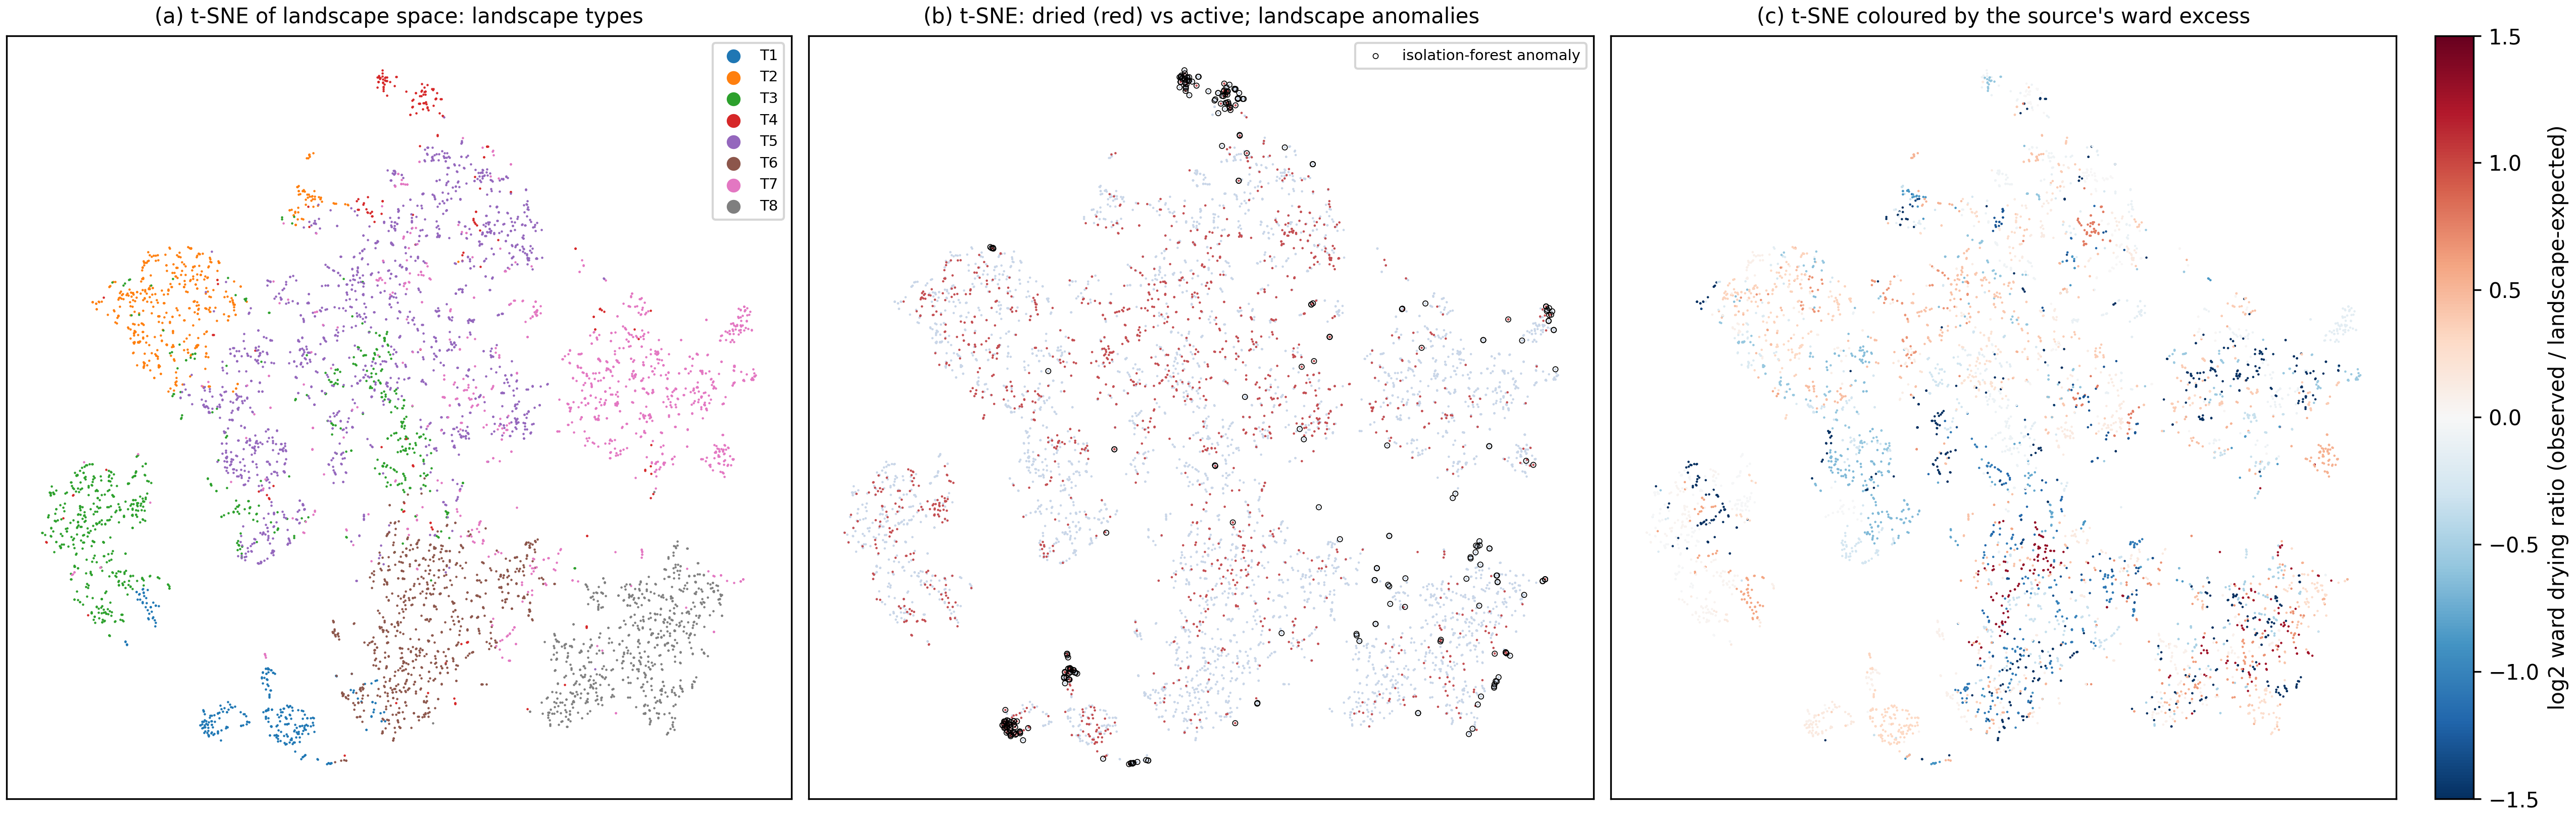

In [9]:
fig("un_embedding.png")

## Explore: drying rate by type within each municipality

In [10]:
from src.graph_builder import load_master
df = load_master().merge(pd.read_csv(ROOT / "data/processed/landscape_types.csv"), on="id")
pd.crosstab(df.municipality, df.env_type, values=df.target_dried, aggfunc="mean").round(3)

env_type,T1,T2,T3,T4,T5,T6,T7,T8
municipality,,,,,,,,
Bethanchownk,NaN,NaN,NaN,0.000,NaN,0.429,0.144,0.194
Dhulikhel,0.421,0.250,0.263,0.391,0.109,0.300,0.235,NaN
Namobuudha,NaN,0.122,0.206,0.273,0.203,0.269,0.111,NaN
Panauti,0.235,NaN,NaN,0.118,NaN,0.091,0.150,0.082
Panchkhal,NaN,0.331,0.438,0.143,0.436,NaN,0.536,NaN
Roshi RM,NaN,0.143,0.500,0.172,0.429,0.000,0.174,NaN
Temal,NaN,NaN,NaN,0.342,0.420,NaN,0.336,NaN
